# Ejercicio 7: detectar objetos en un video con YOLOv8

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

Hacer uso de YOLO para detectar objetos en algún video que el usuario cargue al script.

## Qué hace este notebook

Un video es una secuencia de imágenes, así que la idea es la del ejercicio 4 aplicada cuadro por cuadro: se lee cada fotograma con OpenCV, YOLOv8 devuelve las cajas, las clases y la confianza, y se dibujan sobre el fotograma antes de escribirlo en un video nuevo.

Detectar por separado en cada cuadro cuenta el mismo carro decenas de veces (una por fotograma en que aparece). Para saber **cuántos objetos distintos** pasaron por el video se agrega **seguimiento** (tracking): `model.track(..., persist=True)` con el algoritmo **ByteTrack**, que asocia las cajas de un cuadro con las del anterior y les asigna un identificador estable. Así el script reporta dos cosas distintas:

- **Detecciones**: la suma de objetos vistos en todos los cuadros (un carro que dura 100 cuadros aporta 100).
- **Objetos únicos**: cuántos identificadores de seguimiento distintos hubo por clase (ese mismo carro aporta 1).

La función principal es `detectar_video(ruta_video, salida, conf, cada_n)`. Con `cada_n = 1` procesa todos los cuadros; con `cada_n = 3` corre YOLO solo uno de cada tres y en los otros repite las últimas cajas, a cambio de más velocidad.

In [1]:
# En Google Colab hay que instalar las librerias una vez (en local ya vienen instaladas):
# %pip install -q -U ultralytics lapx

import builtins
import os
import time
import urllib.request
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

try:
    from ipykernel.kernelbase import StdinNotImplementedError
except ImportError:
    class StdinNotImplementedError(Exception):
        pass

plt.rcParams["figure.dpi"] = 80
CARPETA = Path("ejercicio7_video")
CARPETA.mkdir(exist_ok=True)
DISPOSITIVO = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("OpenCV:", cv2.__version__, "| dispositivo:", DISPOSITIVO)

OpenCV: 5.0.0 | dispositivo: mps


---

## 1. Cargar el modelo

`yolov8n.pt` es la versión "nano" de **detección** (no de segmentación como en el ejercicio 4): solo entrega caja, clase y confianza, lo que la hace más rápida, algo que importa cuando hay que procesar cientos de cuadros. Reconoce las 80 clases de COCO.

In [2]:
modelo = YOLO("yolov8n.pt")
parametros = sum(p.numel() for p in modelo.model.parameters())
print("Tarea del modelo :", modelo.task)
print("Clases           :", len(modelo.names))
print(f"Parametros       : {parametros / 1e6:.1f} millones")

Tarea del modelo : detect
Clases           : 80
Parametros       : 3.2 millones


---

## 2. El video de ejemplo

Para dejar resultados reproducibles se usa un clip corto de una carretera con tráfico, del sitio **Pexels** (licencia gratuita de Pexels, permite uso sin atribución). El original dura 60 s; con `recortar_video` se conservan solo los **primeros 10 s** para que el repositorio no engorde. Si la descarga falla (sin internet), la función `crear_video_respaldo` arma un video con la imagen `bus.jpg` de Ultralytics con un desplazamiento lento, y el notebook lo dice al usuario.

`abrir_video` valida que el archivo se pueda abrir y tenga cuadros: es la primera defensa contra rutas o formatos inválidos.

In [3]:
URL_EJEMPLO = "https://videos.pexels.com/video-files/854671/854671-sd_640_360_25fps.mp4"
URL_BUS = "https://ultralytics.com/images/bus.jpg"
EJEMPLO = CARPETA / "entrada_carretera.mp4"


def abrir_video(ruta):
    """Abre un video con OpenCV y devuelve (captura, ancho, alto, fps, cuadros). Lanza ValueError si no sirve."""
    cap = cv2.VideoCapture(str(ruta))
    if not cap.isOpened():
        raise ValueError(f"OpenCV no pudo abrir '{ruta}'.")
    ancho, alto = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    cuadros = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if ancho == 0 or alto == 0 or cuadros <= 0:
        raise ValueError(f"'{ruta}' no parece un video valido (sin cuadros).")
    return cap, ancho, alto, fps, cuadros


def crear_escritor(salida, fps, ancho, alto):
    """Prueba codecs compatibles con macOS/QuickTime y devuelve (escritor, codec) con el primero que abra."""
    for codec in ("mp4v", "avc1"):
        w = cv2.VideoWriter(str(salida), cv2.VideoWriter_fourcc(*codec), fps, (ancho, alto))
        if w.isOpened():
            return w, codec
        w.release()
    raise RuntimeError("Ningun codec de video disponible en esta instalacion de OpenCV.")


def recortar_video(origen, destino, segundos=10):
    """Copia los primeros `segundos` del video origen a destino (mp4)."""
    cap, ancho, alto, fps, _ = abrir_video(origen)
    maximo = int(segundos * fps)
    w, _ = crear_escritor(destino, fps, ancho, alto)
    n = 0
    while n < maximo:
        ok, cuadro = cap.read()
        if not ok:
            break
        w.write(cuadro)
        n += 1
    cap.release(); w.release()
    return n


def crear_video_respaldo(destino, segundos=8, fps=25, ancho=640, alto=360):
    """Respaldo sin internet: paneo lento sobre bus.jpg de Ultralytics, con zoom progresivo."""
    tmp = CARPETA / "bus.jpg"
    if not tmp.exists():
        urllib.request.urlretrieve(URL_BUS, tmp)
    img = cv2.imread(str(tmp))
    h, w_ = img.shape[:2]
    escritor, _ = crear_escritor(destino, fps, ancho, alto)
    total = segundos * fps
    for i in range(total):
        t = i / (total - 1)
        cw = int(w_ * (1 - 0.35 * t)); ch = int(cw * alto / ancho)
        x0 = int((w_ - cw) * t); y0 = int(max(0, (h - ch) * 0.5))
        escritor.write(cv2.resize(img[y0:y0 + ch, x0:x0 + cw], (ancho, alto)))
    escritor.release()
    return total


def preparar_video_ejemplo():
    if EJEMPLO.exists():
        return EJEMPLO, "video de Pexels (carretera con trafico)"
    try:
        completo = CARPETA / "_original_pexels.mp4"
        req = urllib.request.Request(URL_EJEMPLO, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r, open(completo, "wb") as f:
            f.write(r.read())
        n = recortar_video(completo, EJEMPLO, segundos=10)
        completo.unlink()
        return EJEMPLO, f"video de Pexels (carretera con trafico), recortado a {n} cuadros"
    except Exception as e:
        print("No se pudo descargar el video de Pexels:", e)
        n = crear_video_respaldo(EJEMPLO)
        return EJEMPLO, "VIDEO DE RESPALDO generado a partir de bus.jpg (no es un video real)"


VIDEO_EJEMPLO, ORIGEN = preparar_video_ejemplo()
cap, ancho, alto, fps, cuadros = abrir_video(VIDEO_EJEMPLO); cap.release()
print("Origen :", ORIGEN)
print(f"Archivo: {VIDEO_EJEMPLO}  ({VIDEO_EJEMPLO.stat().st_size / 1e6:.2f} MB)")
print(f"{ancho}x{alto} px, {fps:.0f} fps, {cuadros} cuadros, {cuadros / fps:.1f} s")

Origen : video de Pexels (carretera con trafico)
Archivo: ejercicio7_video/entrada_carretera.mp4  (2.32 MB)
640x360 px, 25 fps, 250 cuadros, 10.0 s


---

## 3. La función `detectar_video`

Por cada fotograma:

1. Si toca procesarlo (`indice % cada_n == 0`), se llama `modelo.track(cuadro, persist=True, tracker="bytetrack.yaml")`. `persist=True` conserva el estado del seguimiento entre llamadas; sin él, cada cuadro reiniciaría los identificadores.
2. Se dibuja cada caja con su etiqueta `clase #id confianza`, con un color fijo por identificador para poder seguir visualmente a cada objeto.
3. Se acumulan las estadísticas: detecciones por clase, identificadores únicos por clase y número de objetos en ese cuadro.
4. Se escribe el cuadro en el video de salida.

En los cuadros que se saltan (`cada_n > 1`) se repiten las últimas cajas, para que el video conserve su duración original.

**Sobre el conteo único**: ByteTrack puede perder un objeto (por ejemplo, tapado por otro) y reasignarle otro identificador al reaparecer, y en ese caso el mismo carro cuenta dos veces. Los objetos únicos son por tanto una estimación, en general una cota superior.

In [4]:
def color_de(i):
    rng = np.random.default_rng(int(i) * 7919 + 13)
    return tuple(int(v) for v in rng.integers(60, 255, 3))


def dibujar(cuadro, cajas, nombres):
    for (x1, y1, x2, y2, cls, tid, cf) in cajas:
        color = color_de(tid if tid >= 0 else cls)
        cv2.rectangle(cuadro, (x1, y1), (x2, y2), color, 2)
        etiqueta = f"{nombres[cls]} #{tid} {cf:.2f}" if tid >= 0 else f"{nombres[cls]} {cf:.2f}"
        (tw, th), base = cv2.getTextSize(etiqueta, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(cuadro, (x1, max(0, y1 - th - base - 4)), (x1 + tw + 4, y1), color, -1)
        cv2.putText(cuadro, etiqueta, (x1 + 2, max(th, y1 - base - 2)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return cuadro


def detectar_video(ruta_video, salida, conf=0.25, cada_n=1, modelo=modelo, guardar_cuadros=()):
    """Detecta y sigue objetos en un video, escribe el video anotado y devuelve las estadisticas.

    guardar_cuadros: indices de cuadro (0-based) cuyo fotograma anotado se devuelve en 'muestras'.
    """
    cap, ancho, alto, fps, total = abrir_video(ruta_video)
    escritor, codec = crear_escritor(salida, fps, ancho, alto)
    nombres = modelo.names
    detecciones = defaultdict(int)          # clase -> total de detecciones (suma de cuadros)
    ids_por_clase = defaultdict(set)        # clase -> identificadores de tracking distintos
    por_cuadro = []                         # objetos visibles en cada cuadro
    por_cuadro_clase = []                   # dict clase -> cantidad, por cuadro
    muestras = {}
    cajas = []
    procesados = 0
    modelo.predictor = None                 # reinicia el tracker entre videos
    t0 = time.perf_counter()
    i = 0
    while True:
        ok, cuadro = cap.read()
        if not ok:
            break
        if i % cada_n == 0:
            r = modelo.track(cuadro, persist=True, tracker="bytetrack.yaml", conf=conf,
                             device=DISPOSITIVO, verbose=False)[0]
            cajas = []
            if r.boxes is not None and len(r.boxes):
                xyxy = r.boxes.xyxy.cpu().numpy().astype(int)
                clases = r.boxes.cls.cpu().numpy().astype(int)
                confs = r.boxes.conf.cpu().numpy()
                ids = r.boxes.id.cpu().numpy().astype(int) if r.boxes.id is not None else np.full(len(clases), -1)
                cajas = [(*b, c, t, f) for b, c, t, f in zip(xyxy, clases, ids, confs)]
            procesados += 1
            for (*_, c, t, _f) in cajas:
                detecciones[nombres[c]] += 1
                if t >= 0:
                    ids_por_clase[nombres[c]].add(t)
        conteo = defaultdict(int)
        for (*_, c, _t, _f) in cajas:
            conteo[nombres[c]] += 1
        por_cuadro.append(len(cajas))
        por_cuadro_clase.append(dict(conteo))
        anotado = dibujar(cuadro.copy(), cajas, nombres)
        cv2.putText(anotado, f"cuadro {i}  objetos: {len(cajas)}", (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
        if i in guardar_cuadros:
            muestras[i] = anotado.copy()
        escritor.write(anotado)
        i += 1
    dt = time.perf_counter() - t0
    cap.release(); escritor.release()
    return {
        "entrada": str(ruta_video), "salida": str(salida), "codec": codec,
        "ancho": ancho, "alto": alto, "fps_video": fps,
        "cuadros": i, "procesados": procesados, "cada_n": cada_n, "conf": conf,
        "segundos": dt, "fps_proceso": i / dt, "fps_yolo": procesados / dt,
        "detecciones": dict(detecciones),
        "unicos": {k: len(v) for k, v in ids_por_clase.items()},
        "por_cuadro": por_cuadro, "por_cuadro_clase": por_cuadro_clase, "muestras": muestras,
    }


def resumen(res):
    print(f"Entrada : {res['entrada']}")
    print(f"Salida  : {res['salida']}  (codec {res['codec']}, {Path(res['salida']).stat().st_size / 1e6:.2f} MB)")
    print(f"Cuadros : {res['cuadros']} totales, {res['procesados']} pasados por YOLO (cada_n = {res['cada_n']}), conf >= {res['conf']}")
    print(f"Tiempo  : {res['segundos']:.2f} s  ->  {res['fps_proceso']:.1f} cuadros/s de proceso "
          f"(el video original va a {res['fps_video']:.0f} fps)")
    print()
    print(f"{'clase':<14}{'detecciones':>12}{'objetos unicos':>16}")
    for clase in sorted(res["detecciones"], key=res["detecciones"].get, reverse=True):
        print(f"{clase:<14}{res['detecciones'][clase]:>12}{res['unicos'].get(clase, 0):>16}")
    print(f"{'TOTAL':<14}{sum(res['detecciones'].values()):>12}{sum(res['unicos'].values()):>16}")

---

## 4. Ejecución sobre el video de ejemplo

Se piden los cuadros 0, 80, 160 y 240 anotados para dejar cuatro fotogramas de muestra (`ejercicio7_video/muestra_*.png`). Se procesan todos los cuadros (`cada_n = 1`) con confianza mínima 0.30.

In [5]:
SALIDA = CARPETA / "salida_detectada.mp4"
n_total = abrir_video(VIDEO_EJEMPLO)[4]
ELEGIDOS = [0, n_total // 3, 2 * n_total // 3, n_total - 5]
res = detectar_video(VIDEO_EJEMPLO, SALIDA, conf=0.30, cada_n=1, guardar_cuadros=ELEGIDOS)
resumen(res)

Entrada : ejercicio7_video/entrada_carretera.mp4
Salida  : ejercicio7_video/salida_detectada.mp4  (codec mp4v, 3.57 MB)
Cuadros : 250 totales, 250 pasados por YOLO (cada_n = 1), conf >= 0.3
Tiempo  : 13.31 s  ->  18.8 cuadros/s de proceso (el video original va a 25 fps)

clase          detecciones  objetos unicos
car                   1301              18
truck                  202              25
bus                    133              12
person                  17               3
TOTAL                 1653              58


### Fotogramas de muestra

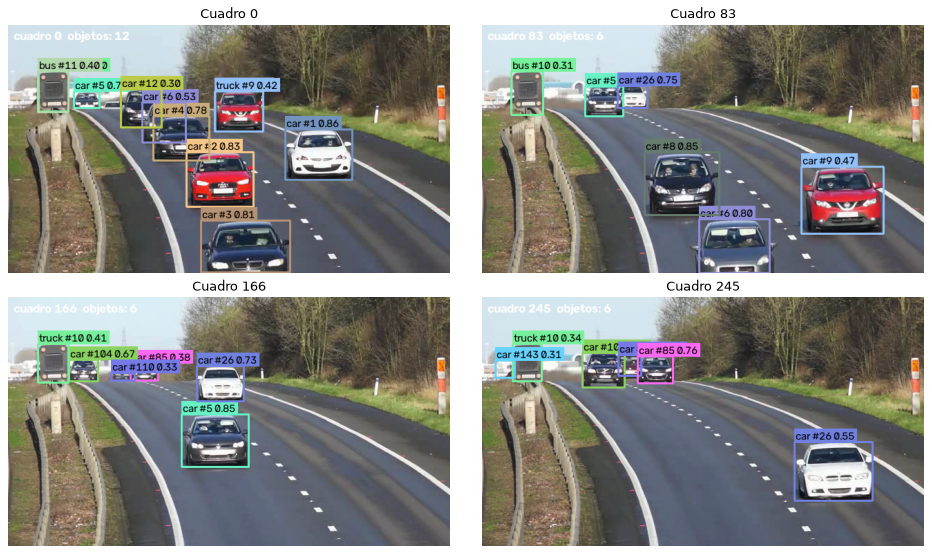

In [6]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
for eje, (i, img) in zip(ejes.ravel(), res["muestras"].items()):
    eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); eje.set_title(f"Cuadro {i}"); eje.axis("off")
    cv2.imwrite(str(CARPETA / f"muestra_{i:04d}.png"), img)
plt.tight_layout(); plt.show()

---

## 5. Conteo por clase y objetos en el tiempo

A la izquierda, detecciones contra objetos únicos por clase: la diferencia entre ambas barras muestra cuánto cuenta de más un detector sin seguimiento. A la derecha, cuántos objetos hay en pantalla en cada instante.

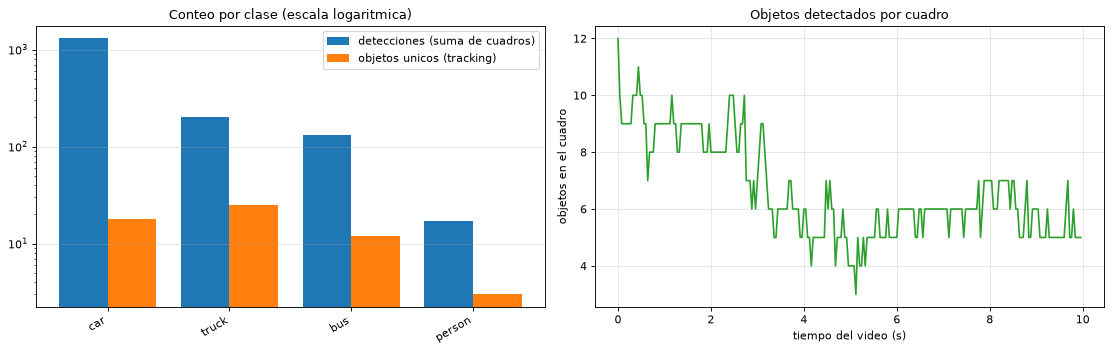

Objetos por cuadro: minimo 3, promedio 6.61, maximo 12 (en el cuadro 0)


In [7]:
def graficar(res, archivo=None):
    clases = sorted(res["detecciones"], key=res["detecciones"].get, reverse=True)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
    x = np.arange(len(clases)); ancho_b = 0.4
    a1.bar(x - ancho_b / 2, [res["detecciones"][c] for c in clases], ancho_b, label="detecciones (suma de cuadros)")
    a1.bar(x + ancho_b / 2, [res["unicos"].get(c, 0) for c in clases], ancho_b, label="objetos unicos (tracking)")
    a1.set_xticks(x); a1.set_xticklabels(clases, rotation=30, ha="right"); a1.set_yscale("log")
    a1.set_title("Conteo por clase (escala logaritmica)"); a1.legend(); a1.grid(axis="y", alpha=0.3)
    t = np.arange(len(res["por_cuadro"])) / res["fps_video"]
    a2.plot(t, res["por_cuadro"], color="tab:green")
    a2.set_xlabel("tiempo del video (s)"); a2.set_ylabel("objetos en el cuadro")
    a2.set_title("Objetos detectados por cuadro"); a2.grid(alpha=0.3)
    plt.tight_layout()
    if archivo:
        plt.savefig(archivo, dpi=100)
    plt.show()

graficar(res, CARPETA / "conteos.png")
pc = np.array(res["por_cuadro"])
print(f"Objetos por cuadro: minimo {pc.min()}, promedio {pc.mean():.2f}, maximo {pc.max()} (en el cuadro {pc.argmax()})")

---

## 6. Verificar que el video de salida sirve

No basta con que `VideoWriter` no falle: se vuelve a abrir el archivo, se cuentan los cuadros realmente decodificables y se comparan con los de entrada.

In [8]:
def verificar_salida(ruta, esperados):
    cap, ancho, alto, fps, declarados = abrir_video(ruta)
    leidos = 0
    while True:
        ok, _ = cap.read()
        if not ok:
            break
        leidos += 1
    cap.release()
    print(f"{ruta}: {ancho}x{alto}, {fps:.0f} fps, cuadros declarados {declarados}, decodificados {leidos}, esperados {esperados}")
    assert leidos == esperados, "El video de salida no tiene la cantidad de cuadros esperada."
    print("OK: el video de salida se abre y tiene todos los cuadros.")

verificar_salida(res["salida"], res["cuadros"])

ejercicio7_video/salida_detectada.mp4: 640x360, 25 fps, cuadros declarados 250, decodificados 250, esperados 250
OK: el video de salida se abre y tiene todos los cuadros.


---

## 7. El usuario carga su video

`pedir_video()` acepta el número del video de ejemplo, la ruta de un archivo propio (por ejemplo la de un video del celular) o `subir` en Google Colab. Valida que el archivo exista y que OpenCV pueda abrirlo; si no, vuelve a preguntar. También pide la confianza mínima y cada cuántos cuadros correr YOLO. Si no hay teclado (por ejemplo en una ejecución automática), usa el ejemplo con valores por defecto.

In [9]:
def pedir_video():
    while True:
        texto = input("Ruta de tu video, 'subir' (solo Colab) o Enter para el de ejemplo: ").strip().strip("'\"")
        if texto in ("", "1"):
            return str(VIDEO_EJEMPLO)
        if texto.lower() == "subir":
            try:
                from google.colab import files
                return next(iter(files.upload()))
            except ImportError:
                print("  'subir' solo funciona en Google Colab.")
                continue
        if not os.path.isfile(texto):
            print("  No encuentro ese archivo. Intenta de nuevo.")
            continue
        try:
            abrir_video(texto)
        except ValueError as e:
            print("  " + str(e))
            continue
        return texto


def pedir_numero(mensaje, defecto, tipo, minimo, maximo):
    while True:
        texto = input(mensaje).strip().replace(",", ".")
        if texto == "":
            return defecto
        try:
            valor = tipo(texto)
        except ValueError:
            print("  Escribe un numero valido.")
            continue
        if minimo <= valor <= maximo:
            return valor
        print(f"  Debe estar entre {minimo} y {maximo}.")


def ejecutar_interactivo(ruta=None, conf=None, cada_n=None, carpeta_salida=CARPETA):
    """Pide video, confianza y salto de cuadros, detecta, resume, verifica y devuelve las estadisticas."""
    try:
        ruta = ruta or pedir_video()
        conf = conf or pedir_numero("Confianza minima entre 0.05 y 0.95 (Enter = 0.30): ", 0.30, float, 0.05, 0.95)
        cada_n = cada_n or pedir_numero("Correr YOLO cada cuantos cuadros, 1 a 10 (Enter = 1): ", 1, int, 1, 10)
    except (EOFError, StdinNotImplementedError):
        print("\nNo hay entrada por teclado en este entorno. Se usa el video de ejemplo con confianza 0.30 y cada_n = 1.")
        ruta, conf, cada_n = ruta or str(VIDEO_EJEMPLO), conf or 0.30, cada_n or 1
    salida = Path(carpeta_salida) / f"{Path(ruta).stem}_detectado.mp4"
    r = detectar_video(ruta, salida, conf=conf, cada_n=cada_n)
    resumen(r)
    verificar_salida(r["salida"], r["cuadros"])
    return r

### Ejecución con entradas simuladas

Este notebook se ejecutó sin teclado, así que las respuestas del usuario están **simuladas** dentro de la misma celda que la llamada (Jupyter restaura `input` en cada celda): primero una ruta que no existe (para mostrar que se rechaza), luego Enter para usar el video de ejemplo, confianza `0.4` y `cada_n = 3`. En una ejecución real, basta con llamar `ejecutar_interactivo()` y escribir las respuestas.

In [10]:
respuestas = iter(["/ruta/que/no/existe.mp4", "", "0.4", "3"])
def input_simulado(mensaje=""):
    r = next(respuestas)
    print(f"{mensaje}{r}   <- entrada simulada")
    return r

_input_real = builtins.input
builtins.input = input_simulado
try:
    res_int = ejecutar_interactivo()
finally:
    builtins.input = _input_real

Ruta de tu video, 'subir' (solo Colab) o Enter para el de ejemplo: /ruta/que/no/existe.mp4   <- entrada simulada
  No encuentro ese archivo. Intenta de nuevo.
Ruta de tu video, 'subir' (solo Colab) o Enter para el de ejemplo:    <- entrada simulada
Confianza minima entre 0.05 y 0.95 (Enter = 0.30): 0.4   <- entrada simulada
Correr YOLO cada cuantos cuadros, 1 a 10 (Enter = 1): 3   <- entrada simulada


Entrada : ejercicio7_video/entrada_carretera.mp4
Salida  : ejercicio7_video/entrada_carretera_detectado.mp4  (codec mp4v, 3.36 MB)
Cuadros : 250 totales, 84 pasados por YOLO (cada_n = 3), conf >= 0.4
Tiempo  : 5.94 s  ->  42.1 cuadros/s de proceso (el video original va a 25 fps)

clase          detecciones  objetos unicos
car                    407              12
truck                   40               7
bus                     29               3
TOTAL                  476              22


ejercicio7_video/entrada_carretera_detectado.mp4: 640x360, 25 fps, cuadros declarados 250, decodificados 250, esperados 250
OK: el video de salida se abre y tiene todos los cuadros.


---

## 8. Comparación: todos los cuadros contra uno de cada tres

Se comparan las dos ejecuciones, `cada_n = 1` (confianza 0.30) y `cada_n = 3` (confianza 0.40). Difieren en dos parámetros a la vez, así que la comparación es una guía y no un experimento controlado; el efecto de `cada_n` en la velocidad es claro, el de la confianza sobre los conteos se mezcla con el del salto.

In [11]:
print(f"{'':<22}{'cada_n=1, conf=0.30':>22}{'cada_n=3, conf=0.40':>22}")
filas = [("cuadros totales", "cuadros"), ("pasados por YOLO", "procesados"), ("segundos", "segundos"), ("cuadros/s de proceso", "fps_proceso")]
for nombre, k in filas:
    a, b = res[k], res_int[k]
    fa = f"{a:.2f}" if isinstance(a, float) else str(a)
    fb = f"{b:.2f}" if isinstance(b, float) else str(b)
    print(f"{nombre:<22}{fa:>22}{fb:>22}")
print(f"{'objetos unicos':<22}{sum(res['unicos'].values()):>22}{sum(res_int['unicos'].values()):>22}")
print(f"{'aceleracion':<22}{res_int['fps_proceso'] / res['fps_proceso']:>22.2f}x")

                         cada_n=1, conf=0.30   cada_n=3, conf=0.40
cuadros totales                          250                   250
pasados por YOLO                         250                    84
segundos                               13.31                  5.94
cuadros/s de proceso                   18.79                 42.12
objetos unicos                            58                    22
aceleracion                             2.24x


---

## Conclusiones

- **YOLOv8 nano detecta bien sobre video y a buena velocidad.** En un Apple M4 (MPS) procesó 250 cuadros de 640x360 a unos 14 a 19 cuadros por segundo según la corrida, con seguimiento incluido, es decir, algo por debajo de tiempo real (el video va a 25 fps). Correr YOLO solo uno de cada tres cuadros subió la velocidad a unos 42 a 53 cuadros por segundo, más rápido que tiempo real, a costa de cajas que se quedan atrás del objeto en los cuadros saltados.
- **Detecciones y objetos únicos son cosas muy distintas.** Con todos los cuadros hubo 1653 detecciones pero solo 58 identificadores únicos. Contar detecciones por cuadro habría sobrestimado el tráfico por un factor de casi 30.
- **Aun así, 58 es una cota superior, no el número real de vehículos.** El clip tiene del orden de una veintena de vehículos. El exceso viene de dos fuentes visibles en el video: los vehículos lejanos, pequeños, aparecen y desaparecen del umbral de confianza y ByteTrack les reasigna otro identificador, y la clase de un mismo vehículo a veces cambia entre `car`, `truck` y `bus`, lo que también parte su historia en dos. Por eso `truck` (25 únicos) y `bus` (12) quedan inflados frente a `car` (18).
- **Hay falsos positivos.** La caja gris del borde izquierdo (un panel de la carretera) se etiqueta como `truck`, y las pocas detecciones de `person` son dudosas. Subir la confianza (0.4 en la segunda ejecución) los reduce, pero también pierde vehículos lejanos.
- **El video de salida se verificó**: se reabrió con OpenCV y decodificó los 250 cuadros a 640x360 y 25 fps, con el codec `mp4v`. Ese codec se abre con OpenCV; en QuickTime suele reproducirse, y si algún reproductor lo rechaza se puede recodificar con `ffmpeg -i entrada.mp4 -c:v libx264 salida.mp4`.

**Limitaciones:** el clip de ejemplo es corto (10 s) y de una sola escena; el seguimiento por ByteTrack usa solo movimiento y cajas, sin apariencia, por lo que no recupera bien a un objeto que desaparece y vuelve; y `yolov8n` es el modelo más pequeño, con `yolov8s` o `yolov8m` se esperan menos falsos positivos y menos cambios de clase, a cambio de menos velocidad.